In [1]:
from function_library import *

In [2]:
#load the needed dataset
datenpfad = 'D:/AG_USB/Mohamed_AG_Schock/Datasets/lmu_final_training.csv'
df_lmu_big = pd.read_csv(datenpfad)

df_lmu_big = df_lmu_big.drop(columns=['Unnamed: 0', 'ID', 'X', 'RandomisationID'])# 'Datum',

datenpfad = 'D:/AG_USB/Mohamed_AG_Schock/Datasets/lmu_final_training_mice.csv'
df_3d_GFR_mice = pd.read_csv(datenpfad)

# **Data cleaning and imputation**


In [7]:
# Clean the initial DataFrame using the clean_data function with specified parameters.
df = clean_data(df_lmu_big, encode=True, fillna=False, Troponin=True, log=True, scaling=True)

# List of columns to be dropped from the DataFrame.
col_to_drop = ['Death_in3d', 'DaystillDeath', 'Death_inHospitalStay', 'Death_inICUStay',
                'DaysTillICUStay_end', 'Death_in1w', 'Death_in2w', 'Death_in3w',
                'CPConICUDischarge_CPC1', 'CPConICUDischarge_CPC2', 
                'CPConICUDischarge_CPC3', 'CPConICUDischarge_CPC4',  'Datum',
                'CPConICUDischarge_CPC5', 'Death_in24h']

# Set a threshold for the maximum proportion of missing values allowed in each row (10%).
threshold = 0.1

# Filter the DataFrame to keep only rows where the proportion of missing values is less than the threshold.
df_filtered = df[df.isnull().mean(axis=1) < threshold]

# Create a copy of the columns specified in col_to_drop from the filtered DataFrame for later use.
df_drop = df_filtered[col_to_drop].copy()

# Drop the specified columns from the filtered DataFrame.
df_filtered = df_filtered.drop(columns=col_to_drop)

In [8]:
# Initialize an IterativeImputer to handle missing values in the DataFrame.
imputer = IterativeImputer(max_iter=5, random_state=0)

# Apply the imputer to the filtered DataFrame and create a new DataFrame with imputed values.
# The fit_transform method fits the imputer on the data and transforms it simultaneously.
df_imputed = pd.DataFrame(imputer.fit_transform(df_filtered), columns=df_filtered.columns)


In [9]:
# Set the index of the df_drop DataFrame to match the index of the imputed DataFrame.
df_drop = df_drop.set_index(df_imputed.index)

# Concatenate the imputed DataFrame and the dropped columns DataFrame along the columns axis (axis=1).
# This creates a new DataFrame that combines the imputed values with the original values of the dropped columns.
df_3d_GFR_mice = pd.concat([df_imputed, df_drop], axis=1)

In [10]:
df_3d_GFR_mice.to_csv("df_3d_GFR_mice.csv", index=False)  # Save the cleaned SICDB dataset

# **Classifier selection**


In [17]:
# Create a copy of the DataFrame df_3d_GFR_mice to avoid modifying the original data.
df = df_3d_GFR_mice.copy()

# Clean the copied DataFrame using the clean_data function with specified parameters.
# The function performs categorical encoding, but doesn't fill missing values, apply logarithmic transformation, or scaling.
df = clean_data(df, encode=True, fillna=False, Troponin=True, log=False, scaling=False)

# List of columns to be dropped from the DataFrame, which are likely related to death outcomes and health status.
col_to_drop = ['Death_in3d', 'DaystillDeath', 'Death_inHospitalStay', 'Death_inICUStay',
                'DaysTillICUStay_end', 'Death_inICUStay', 'Death_in1w', 
                'Death_in2w', 'Death_in3w', 'CPConICUDischarge_CPC1', 
                'CPConICUDischarge_CPC2', 'CPConICUDischarge_CPC3', 
                'CPConICUDischarge_CPC4', 'CPConICUDischarge_CPC5']

# Drop the specified columns from the DataFrame. This helps in focusing on the features needed for modeling.
df = df.drop(col_to_drop, axis=1)

# Specify the label/target variable for classification. In this case, it's whether a patient died within 24 hours.
label = 'Death_in24h'

# Separate the features (X) from the target variable (y). The target variable is removed from the features DataFrame.
X = df.drop(label, axis=1)  # Features DataFrame
y = df[label]                # Target variable

# Split the data into training and testing sets.
# 20% of the data will be set aside for testing, and the data will not be shuffled to maintain the original order.
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)


c:\Users\mmeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression
0.7205882352941176
AdaBoostClassifier
0.8137254901960784
BaggingClassifier
0.8137254901960784
KNearest
0.6813725490196079


c:\Users\mmeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
c:\Users\mmeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC
0.6372549019607843
SupportVectorClassifier
0.5931372549019608
DecisionTreeClassifier
0.7696078431372549
RandomForestClassifier
0.8284313725490197
GradientBoostingClassifier
0.8137254901960784
GaussianNB
0.696078431372549
MLPClassifier
0.7156862745098039
LinearDiscriminantAnalysis
0.7156862745098039


c:\Users\mmeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\discriminant_analysis.py:935: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


QuadraticDiscriminantAnalysis
0.7450980392156863
SGDClassifier
0.5588235294117647
NearestCentroid
0.5931372549019608
ExtraTreeClassifier
0.6862745098039216
XGBClassifier
0.8235294117647058


... (20 outputs left out)

c:\Users\mmeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(
c:\Users\mmeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVC
0.6354679802955665
SupportVectorClassifier
0.5714285714285714
DecisionTreeClassifier
0.7192118226600985
RandomForestClassifier
0.8325123152709359
GradientBoostingClassifier
0.8078817733990148
GaussianNB
0.7093596059113301
MLPClassifier
0.7635467980295566
LinearDiscriminantAnalysis
0.7931034482758621


c:\Users\mmeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\discriminant_analysis.py:935: UserWarning: Variables are collinear
  warnings.warn("Variables are collinear")


QuadraticDiscriminantAnalysis
0.8325123152709359
SGDClassifier
0.4876847290640394
NearestCentroid
0.5566502463054187
ExtraTreeClassifier
0.6995073891625616
XGBClassifier
0.8275862068965517


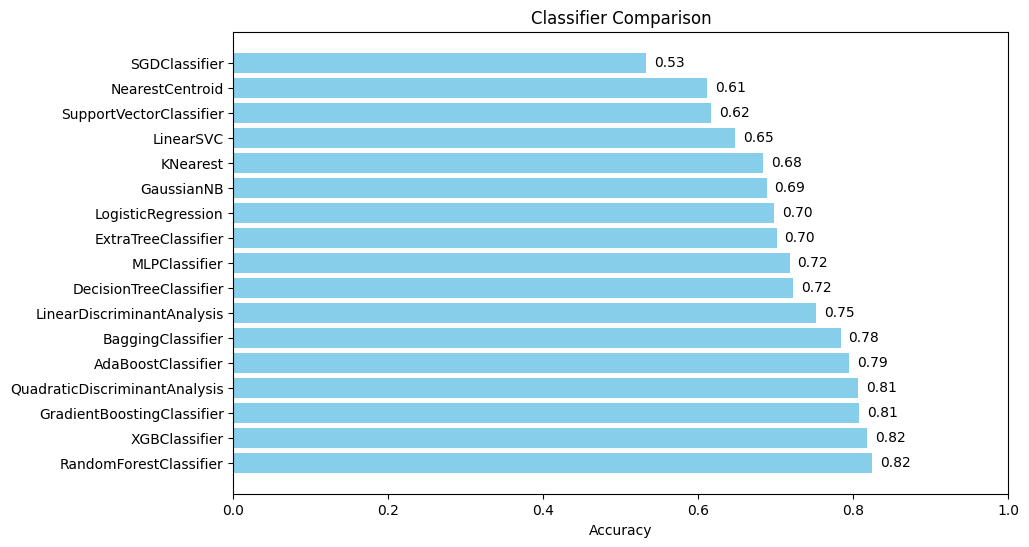

RandomForestClassifier:
  accuracy: 0.8240
  precision: 0.8331
  recall: 0.8182
  f1: 0.8254
  auc: 0.8241
  fpr: 0.1700
  fnr: 0.1818
---------------------------------------------
XGBClassifier:
  accuracy: 0.8181
  precision: 0.8261
  recall: 0.8143
  f1: 0.8198
  auc: 0.8181
  fpr: 0.1780
  fnr: 0.1857
---------------------------------------------
GradientBoostingClassifier:
  accuracy: 0.8073
  precision: 0.8225
  recall: 0.7930
  f1: 0.8072
  auc: 0.8075
  fpr: 0.1780
  fnr: 0.2070
---------------------------------------------
QuadraticDiscriminantAnalysis:
  accuracy: 0.8064
  precision: 0.8979
  recall: 0.6985
  f1: 0.7844
  auc: 0.8083
  fpr: 0.0820
  fnr: 0.3015
---------------------------------------------
AdaBoostClassifier:
  accuracy: 0.7945
  precision: 0.8005
  recall: 0.7949
  f1: 0.7974
  auc: 0.7944
  fpr: 0.2060
  fnr: 0.2051
---------------------------------------------
BaggingClassifier:
  accuracy: 0.7837
  precision: 0.8096
  recall: 0.7544
  f1: 0.7803
  auc: 0.

In [ ]:

# Concatenate features (X) and target variable (y) into a single DataFrame for manipulation.
df = pd.concat([X, y], axis=1)

# Shuffle the DataFrame to ensure randomness in sampling.
df = df.sample(frac=1)

# Create separate DataFrames for deceased (label = 1) and alive (label = 0) samples.
dead_df_mix = df.loc[df[label] == 1]
alive_df_mix = df.loc[df[label] == 0][:500]  # Limit to 500 samples for the alive group

# Combine the sampled dead and alive DataFrames to create a balanced dataset for 24-hour outcomes.
df_24h = pd.concat([dead_df_mix, alive_df_mix], axis=0)

# Separate features and labels from the new balanced dataset.
X_train_smote = df_24h.drop(label, axis=1)  # Features
y_train_smote = df_24h[label]                # Target variable

# Apply ADASYN (a type of SMOTE) for oversampling the minority class.
smote = ADASYN(sampling_strategy='auto')  # Automatically adjust the sampling strategy
X, y = smote.fit_resample(X_train_smote, y_train_smote)  # Resample features and labels

# Define a dictionary of classifiers to evaluate.
classifiers = {
    "LogisticRegression": LogisticRegression(),
    "AdaBoostClassifier": AdaBoostClassifier(),
    "BaggingClassifier": BaggingClassifier(),
    "KNearest": KNeighborsClassifier(),
    "LinearSVC": LinearSVC(),
    "SupportVectorClassifier": SVC(),
    "DecisionTreeClassifier": DecisionTreeClassifier(),
    "RandomForestClassifier": RandomForestClassifier(),
    "GradientBoostingClassifier": GradientBoostingClassifier(),
    "GaussianNB": GaussianNB(),
    "MLPClassifier": MLPClassifier(),
    "LinearDiscriminantAnalysis": LinearDiscriminantAnalysis(),
    "QuadraticDiscriminantAnalysis": QuadraticDiscriminantAnalysis(),
    "SGDClassifier": SGDClassifier(),
    "NearestCentroid": NearestCentroid(),
    #"GaussianProcessClassifier": GaussianProcessClassifier(),  # Commented out, can be added later
    "ExtraTreeClassifier": ExtraTreeClassifier(),
    "XGBClassifier": xgb.XGBClassifier()
}

# Function to evaluate classifiers using cross-validation.
def cross_val_evaluation(X, y, classifiers, cv=3):
    # Initialize Stratified K-Folds cross-validator to maintain the proportion of classes in each fold.
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=42)
    # Create a dictionary to store evaluation metrics for each classifier.
    results = {name: {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'auc': [], 'fpr': [], 'fnr': []} for name in classifiers.keys()}
    
    # Perform cross-validation.
    for train_index, test_index in skf.split(X, y):
        X_train_res, X_test_fold = X.iloc[train_index], X.iloc[test_index]
        y_train_res, y_test_fold = y.iloc[train_index], y.iloc[test_index]
        
        # Note: SMOTE is not applied here during cross-validation splits, to avoid data leakage.
        
        # Evaluate each classifier.
        for name, clf in classifiers.items():
            clf.fit(X_train_res, y_train_res)  # Train the classifier
            y_pred = clf.predict(X_test_fold)  # Make predictions
            
            # Calculate evaluation metrics.
            accuracy = accuracy_score(y_test_fold, y_pred)
            precision = precision_score(y_test_fold, y_pred)
            recall = recall_score(y_test_fold, y_pred)
            f1 = f1_score(y_test_fold, y_pred)
            auc = roc_auc_score(y_test_fold, y_pred)
            tn, fp, fn, tp = confusion_matrix(y_test_fold, y_pred).ravel()  # True negatives, false positives, false negatives, true positives
            fpr = fp / (fp + tn)  # False Positive Rate
            fnr = fn / (fn + tp)  # False Negative Rate
            
            # Store the results.
            results[name]['accuracy'].append(accuracy)
            results[name]['precision'].append(precision)
            results[name]['recall'].append(recall)
            results[name]['f1'].append(f1)
            results[name]['auc'].append(auc)
            results[name]['fpr'].append(fpr)
            results[name]['fnr'].append(fnr)
            print(name)  # Print the name of the classifier
            print(accuracy)  # Print the accuracy for each fold
    
    return results  # Return the results for all classifiers

# Perform cross-validation and evaluate all classifiers.
results = cross_val_evaluation(X, y, classifiers, cv=5)

# Summarize the results by calculating the mean of each metric for each classifier.
summary = {name: {metric: np.mean(scores) for metric, scores in metrics.items()} for name, metrics in results.items()}

# Sort the summary results based on accuracy in descending order.
sorted_summary = dict(sorted(summary.items(), key=lambda item: item[1]['accuracy'], reverse=True))

# Create a horizontal bar chart to visualize the accuracy of each classifier.
plt.figure(figsize=(10, 6))
bars = plt.barh(list(sorted_summary.keys()), [metrics['accuracy'] for metrics in sorted_summary.values()], color='skyblue')
plt.xlabel('Accuracy')
plt.title('Classifier Comparison')
plt.xlim(0, 1)  # Set x-axis limits from 0 to 1

# Display accuracy values as text labels next to the bars.
for bar, acc in zip(bars, [metrics['accuracy'] for metrics in sorted_summary.values()]):
    plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2, f'{acc:.2f}', ha='left', va='center')

plt.show()  # Show the plot

# Print detailed results for each classifier, including all evaluation metrics.
for name, metrics in sorted_summary.items():
    print(f"{name}:")
    for metric, score in metrics.items():
        print(f"  {metric}: {score:.4f}")
    print('---' * 15)  # Separator for readability


C:\Users\mmeth\AppData\Local\Temp\ipykernel_20188\691283502.py:12: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colors = plt.cm.get_cmap('tab10', len(metrics))


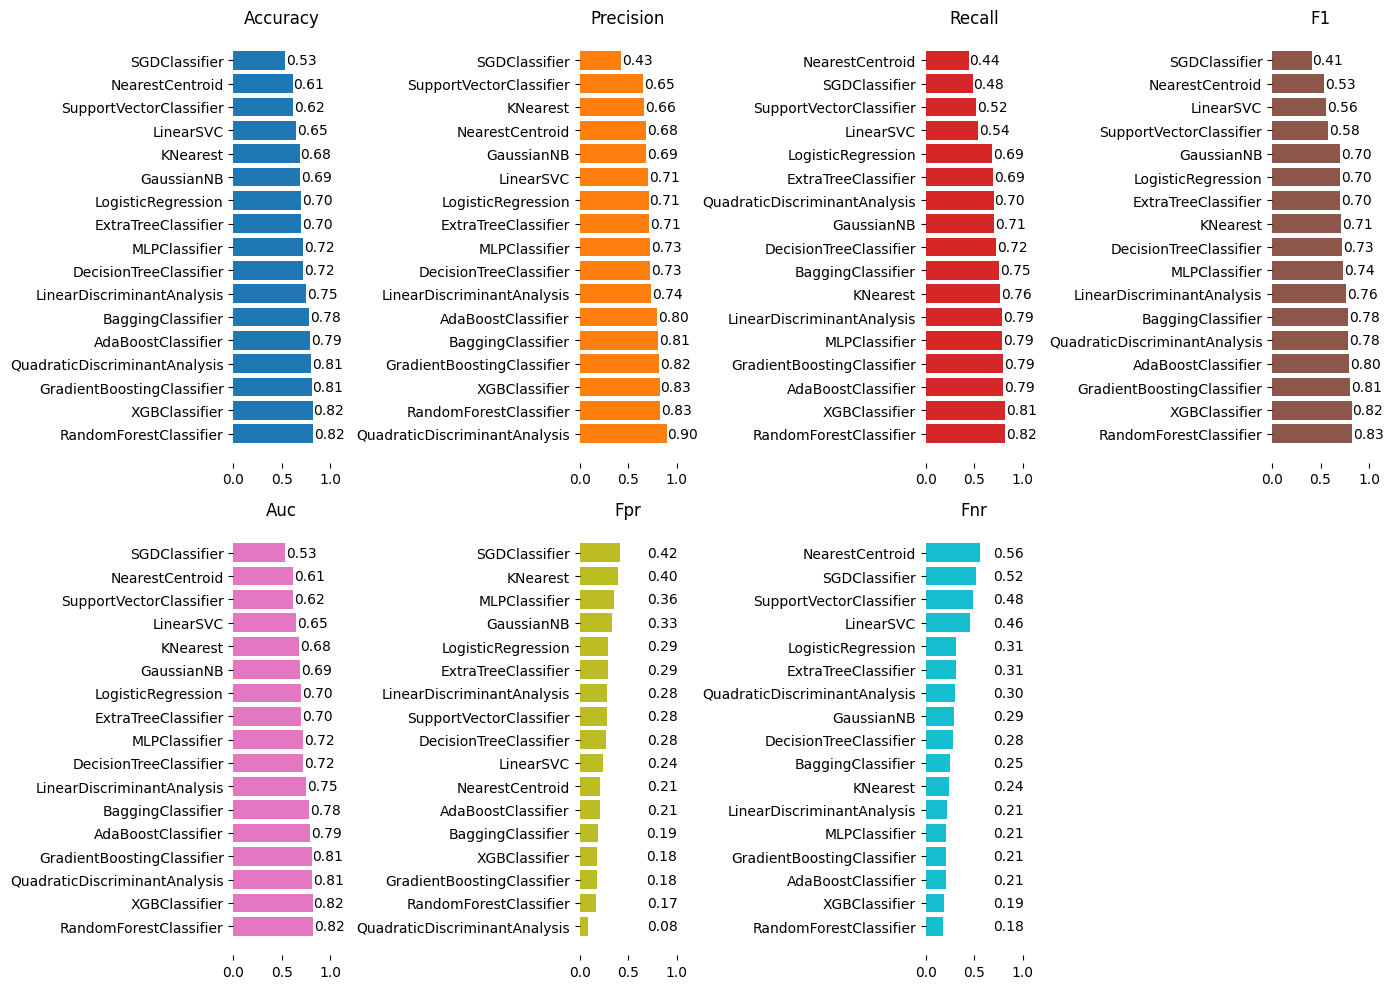

In [20]:
# Import the necessary libraries for plotting and numerical operations
import matplotlib.pyplot as plt
import numpy as np

# Create a list of the evaluation metrics to visualize
metrics = ['accuracy', 'precision', 'recall', 'f1', 'auc', 'fpr', 'fnr']

# Initialize the figure for the plots with a specified size
plt.figure(figsize=(14, 10))

# Create a color map for the metrics using the 'tab10' colormap
colors = plt.cm.get_cmap('tab10', len(metrics))

# Loop through each metric to create a subplot for each
for idx, metric in enumerate(metrics):
    # Create a subplot in a 2-row by 4-column layout
    ax = plt.subplot(2, 4, idx + 1)
    
    # Sort the classifiers based on the mean value of the current metric
    # Reverse the order for metrics that should have higher values (like accuracy, precision)
    sorted_classifiers = sorted(results.keys(), key=lambda x: np.mean(results[x][metric]), reverse=(metric not in ['fpr', 'fnr']))
    
    # Extract the mean values of the metric for the sorted classifiers
    metric_means = [np.mean(results[clf][metric]) for clf in sorted_classifiers]
    
    # Create a horizontal bar plot for the current metric
    bars = plt.barh(sorted_classifiers, metric_means, color=colors(idx))
    
    # Add the metric name as the title of the subplot
    plt.title(metric.capitalize())
    
    # Adjust the x-axis limits depending on the metric
    plt.xlim(0, 1)  # Set x-axis limits from 0 to 1 for all metrics
    
    # Display the mean values next to the bars
    for bar, val in zip(bars, metric_means):
        # For false positive rate (fpr) and false negative rate (fnr), position the text on the right
        if metric in ['fpr', 'fnr']:
            plt.text(1.01,  # Position the text slightly to the right of the bar
                     bar.get_y() + bar.get_height() / 2,
                     f'{val:.2f}', ha='right', va='center')  # Format the value to 2 decimal places
        else:
            # For other metrics, position the text to the left of the bar
            plt.text(val + 0.01, 
                     bar.get_y() + bar.get_height() / 2, 
                     f'{val:.2f}', ha='left', va='center')
    
    # Remove the spines (the outer box lines) for a cleaner look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)

# Optimize the layout of the subplots to prevent overlap
plt.tight_layout()

# Display the plot
plt.show()


# **Features selection**


In [14]:
# Create a copy of the original DataFrame to avoid modifying the original data
df = df_lmu_big.copy()
df = df.drop(columns=['Datum'])# 'Datum',


# Clean the data by applying the clean_data function with specified parameters
# - encode: True (to encode categorical variables)
# - fillna: False (no imputation for missing values)
# - Troponin: True (include Troponin-related data)
# - log: False (no log transformation)
# - scaling: False (no feature scaling)
df = clean_data(df, encode=True, fillna=False, Troponin=True, log=False, scaling=False)

# Define the columns to drop from the DataFrame for the analysis
col_to_drop = [
    'Death_in3d', 'DaystillDeath', 'Death_inHospitalStay', 
    'DaysTillICUStay_end', 'Death_inICUStay', 'Death_in1w', 'Death_in2w', 
    'Death_in3w', 'CPConICUDischarge_CPC1', 'CPConICUDischarge_CPC2', 
    'CPConICUDischarge_CPC3', 'CPConICUDischarge_CPC4', 'CPConICUDischarge_CPC5'
]

# Drop the specified columns from the DataFrame
df = df.drop(col_to_drop, axis=1)

# Set the label variable to be predicted (target variable)
label = 'Death_in24h'

# Define feature set X by dropping the label from the DataFrame
X = df.drop(label, axis=1)

# Define target variable y as the label column
y = df[label]

# Split the dataset into training and testing sets (80% train, 20% test)
# shuffle=False ensures that the split maintains the order of the data
X, X_test, y, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Combine features X and target y into a single DataFrame for further processing
df = pd.concat([X, y], axis=1)

# Shuffle the DataFrame to mix the rows randomly for better training
df = df.sample(frac=1)

# Separate the DataFrame into two subsets based on the target variable
dead_df_mix = df.loc[df[label] == 1]  # Subset of patients who died within 24 hours
alive_df_mix = df.loc[df[label] == 0][:2000]  # Subset of 2000 patients who survived

# Concatenate the two subsets to create a balanced dataset for analysis
df_24h = pd.concat([dead_df_mix, alive_df_mix], axis=0)

# Update the feature set X and target variable y based on the balanced dataset
X = df_24h.drop(label, axis=1)  # Features from the balanced dataset
y = df_24h[label]  # Target variable from the balanced dataset


In [16]:
# Define the objective function for Optuna to optimize hyperparameters
def objective(trial, X=X, y=y):
    # Split the data into training and evaluation sets (85% train, 15% eval)
    # Stratify ensures that the distribution of the target variable is preserved
    X_train, X_eval, y_train, y_eval = train_test_split(X, y, test_size=0.15, stratify=y)

    # Define the hyperparameters to be optimized using trial.suggest methods
    param = {
        'objective': 'binary:logistic',  # Specify the learning task and objective function
        'lambda': trial.suggest_float('lambda', 0.0001, 10.0),  # L2 regularization term
        'alpha': trial.suggest_float('alpha', 0.0001, 10.0),    # L1 regularization term
        'eta': trial.suggest_float('eta', 0.001, 0.1),          # Step size shrinkage (learning rate)
        'learning_rate': trial.suggest_float('learning_rate', 0.008, 0.3),  # Alternative learning rate parameter
        'n_estimators': trial.suggest_int('n_estimators', 50, 1000),  # Number of trees in the ensemble
        'max_depth': trial.suggest_int('max_depth', 3, 20),        # Maximum depth of a tree
        'random_state': trial.suggest_categorical('random_state', [2020]),  # Fixed random seed for reproducibility
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 30),  # Minimum sum of instance weight (hessian) needed in a child
        'gamma': trial.suggest_int('gamma', 0.009, 10),             # Minimum loss reduction required to make a further partition
        'scale_pos_weight': trial.suggest_int('scale_pos_weight', 8, 8),  # Control the balance of positive and negative weights
        'max_delta_step': trial.suggest_int('max_delta_step', 1, 1)  # Maximum delta step we allow each tree's weight estimation
    }

    # Define the pruning callback to stop trials early if they are not promising
    pruning_callback = XGBoostPruningCallback(trial, "validation_0-aucpr")

    # Initialize the XGBoost classifier with the suggested parameters
    model = xgb.XGBClassifier(**param, early_stopping_rounds=10, device="cuda", eval_metric="aucpr", callbacks=[pruning_callback])
    
    # Fit the model to the training data and evaluate on the evaluation set
    model.fit(X_train, y_train, eval_set=[(X_eval, y_eval)], verbose=False)

    # Get the predicted probabilities for the positive class
    pred_proba = model.predict_proba(X_eval)[:, 1]
    
    # Calculate the ROC AUC score for the evaluation set predictions
    score = roc_auc_score(y_eval, pred_proba)

    # Return the calculated score as the objective metric for Optuna
    return score

In [17]:
# Set the direction of optimization to maximize the objective score
direction = 'maximize'

# Create a new Optuna study for hyperparameter optimization
study = optuna.create_study(direction=direction)

# Optimize the objective function over a specified number of trials
study.optimize(objective, n_trials=50)

# Print the number of completed trials and the best trial parameters found
print('Number of finished trials:', len(study.trials))
print('Best trial:', study.best_trial.params)

# Store the best hyperparameters from the study for final model training
Best_trial = study.best_trial.params

# Initialize the final XGBoost model using the best parameters found during optimization
final_model = xgb.XGBClassifier(**Best_trial, eval_metric="aucpr", device="cuda")

# Fit the final model to the entire dataset
final_model.fit(X, y, verbose=True)

Number of finished trials: 50
Best trial: {'lambda': 6.8309699236292705, 'alpha': 9.442078783288345, 'eta': 0.08618286524684955, 'learning_rate': 0.2494190660692911, 'n_estimators': 100, 'max_depth': 5, 'random_state': 2020, 'min_child_weight': 8, 'gamma': 1, 'scale_pos_weight': 8, 'max_delta_step': 1}


XGBClassifier(alpha=9.442078783288345, base_score=None, booster=None,
              callbacks=None, colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device='cuda', early_stopping_rounds=None,
              enable_categorical=False, eta=0.08618286524684955,
              eval_metric='aucpr', feature_types=None, gamma=1,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, lambda=6.8309699236292705,
              learning_rate=0.2494190660692911, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None, max_delta_step=1,
              max_depth=5, max_leaves=None, min_child_weight=8, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100, ...)

### Model Evaluation

accuracy: 0.9947757945145842
precision: 0.9611650485436893
recall: 1.0
f1: 0.9801980198019802
roc_auc: 1.0
aucpr: 1.0
Fp+Fn: 12
auc_score: 1.0


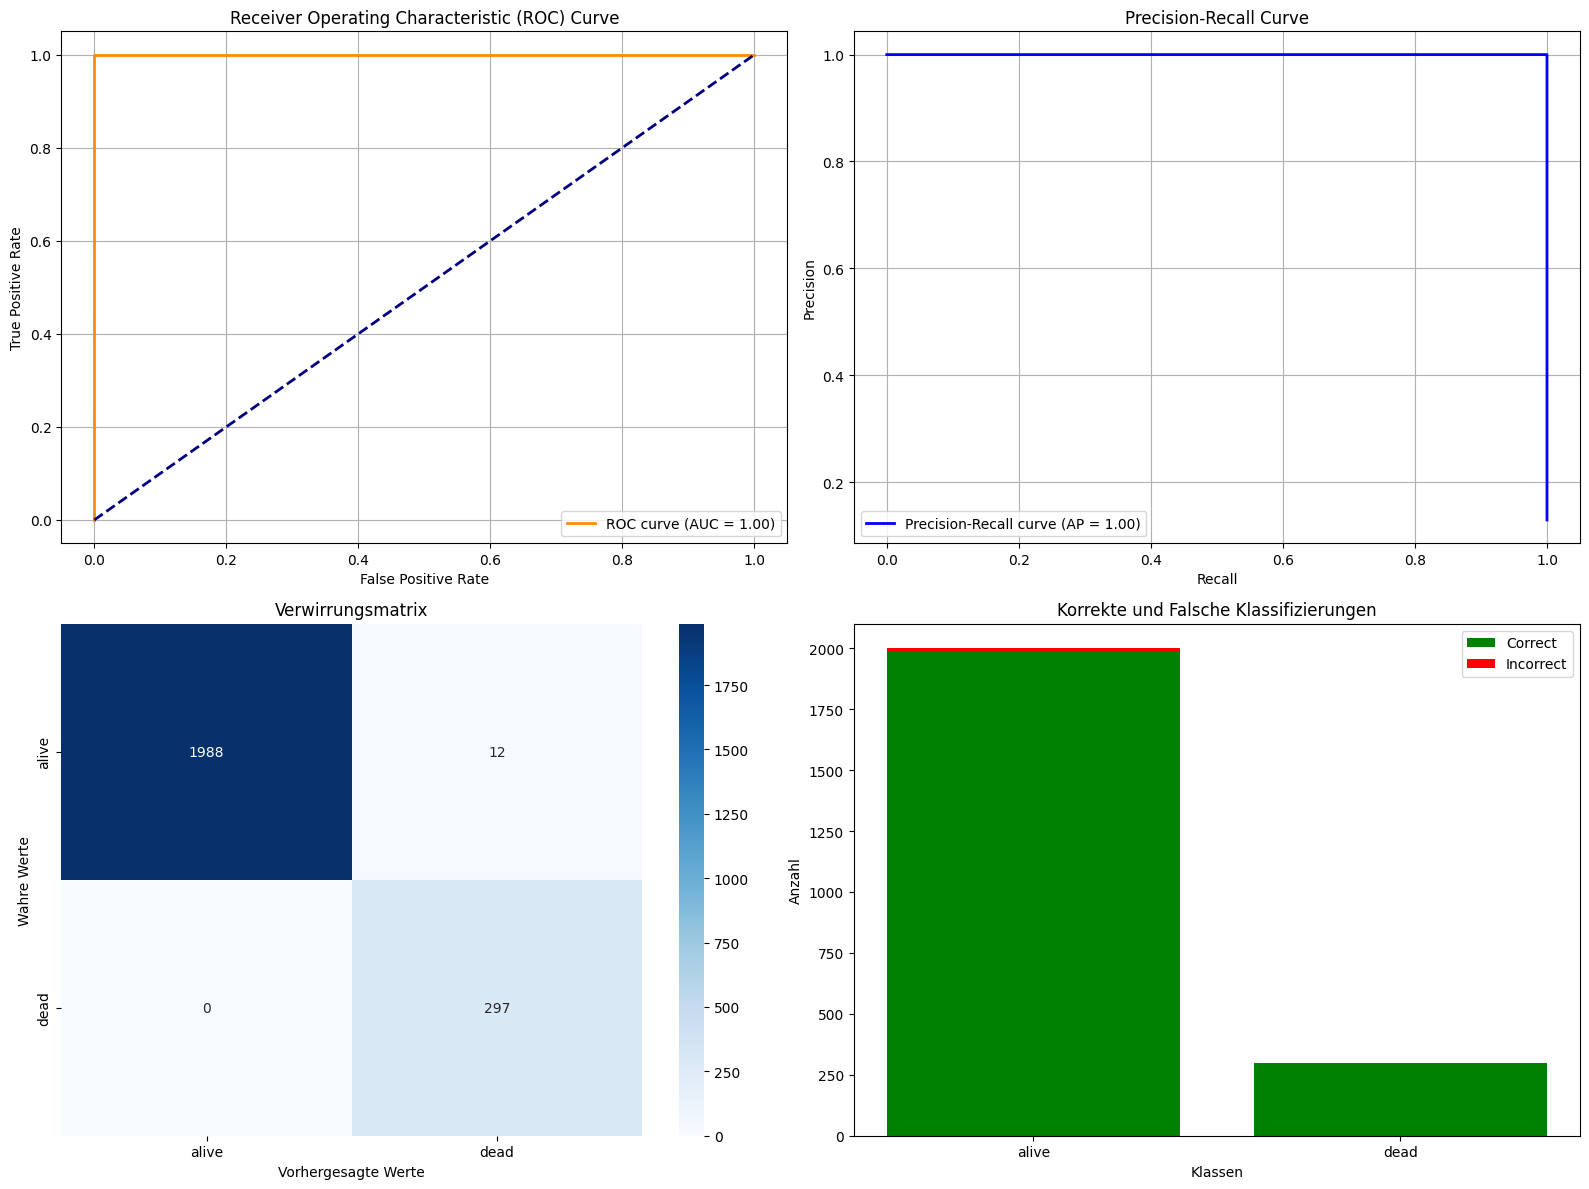

In [8]:
# Import the precision-recall curve metric
from sklearn.metrics import precision_recall_curve

# Predict the labels and probabilities for the dataset using the trained final model
preds = final_model.predict(X)  # Predicted labels (0 or 1)
pred_proba = final_model.predict_proba(X)[:, 1]  # Predicted probabilities for the positive class

# Calculate various performance metrics
accuracy = accuracy_score(y, preds)  # Overall accuracy of the model
precision = precision_score(y, preds)  # Precision: true positives / (true positives + false positives)
recall = recall_score(y, preds)  # Recall: true positives / (true positives + false negatives)
f1 = f1_score(y, preds)  # F1 Score: harmonic mean of precision and recall
roc_auc = roc_auc_score(y, pred_proba)  # Area Under the ROC Curve (AUC)
aucpr = average_precision_score(y, pred_proba)  # Average Precision Score (AUC-PR)

# Generate the confusion matrix and extract TN, FP, FN, TP
conf_matrix = confusion_matrix(y, preds)
tn, fp, fn, tp = conf_matrix.ravel()  # True Negatives, False Positives, False Negatives, True Positives
FpFn = fp + fn  # Total of false positives and false negatives

# Calculate ROC curve metrics
fpr, tpr, thresholds = roc_curve(y, pred_proba)  # False Positive Rate and True Positive Rate
auc_score = auc(fpr, tpr)  # AUC score based on the ROC curve

# Print out the calculated metrics for evaluation
print('accuracy:', accuracy)
print('precision:', precision)
print('recall:', recall)
print('f1:', f1)
print('roc_auc:', roc_auc)
print('aucpr:', aucpr)
print('Fp+Fn:', FpFn)
print('auc_score:', auc_score)

# Calculate Precision, Recall, and Thresholds for the Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(y, pred_proba)  # Compute precision-recall pairs
average_precision = average_precision_score(y, pred_proba)  # Average precision score

# Set up a figure with 2x2 subplots for visualizing the results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot ROC Curve (top left)
axes[0, 0].plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(auc_score))
axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Diagonal line for random guessing
axes[0, 0].set_xlabel('False Positive Rate')  # Label for x-axis
axes[0, 0].set_ylabel('True Positive Rate')  # Label for y-axis
axes[0, 0].set_title('Receiver Operating Characteristic (ROC) Curve')  # Title for the plot
axes[0, 0].legend()  # Display legend
axes[0, 0].grid(True)  # Add a grid to the plot

# Plot Precision-Recall Curve (top right)
axes[0, 1].plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve (AP = {:.2f})'.format(average_precision))
axes[0, 1].set_xlabel('Recall')  # Label for x-axis
axes[0, 1].set_ylabel('Precision')  # Label for y-axis
axes[0, 1].set_title('Precision-Recall Curve')  # Title for the plot
axes[0, 1].legend()  # Display legend
axes[0, 1].grid(True)  # Add a grid to the plot

# Plot Confusion Matrix (bottom left)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["alive", "dead"], yticklabels=["alive", "dead"], ax=axes[1, 0])
axes[1, 0].set_xlabel("Vorhergesagte Werte")  # Label for x-axis (Predicted Values)
axes[1, 0].set_ylabel("Wahre Werte")  # Label for y-axis (True Values)
axes[1, 0].set_title("Verwirrungsmatrix")  # Title for the plot

# Barplot for correct and incorrect classifications (bottom right)
correct_labels = ["alive", "dead"]  # Class labels
correct_counts = [conf_matrix[i, i] for i in range(len(correct_labels))]  # Correct classifications for each class
incorrect_counts = [sum(conf_matrix[i, :]) - conf_matrix[i, i] for i in range(len(correct_labels))]  # Incorrect classifications

# Create stacked bar plot for correct and incorrect classifications
axes[1, 1].bar(correct_labels, correct_counts, color='green', label='Correct')  # Bar for correct classifications
axes[1, 1].bar(correct_labels, incorrect_counts, bottom=correct_counts, color='red', label='Incorrect')  # Stacked bar for incorrect classifications
axes[1, 1].set_xlabel('Klassen')  # Label for x-axis (Classes)
axes[1, 1].set_ylabel('Anzahl')  # Label for y-axis (Count)
axes[1, 1].set_title('Korrekte und Falsche Klassifizierungen')  # Title for the plot
axes[1, 1].legend()  # Display legend

# Adjust the layout to avoid overlap of subplots
plt.tight_layout()

# Show the complete figure with all plots
plt.show()


accuracy: 0.8859298712827341
precision: 0.15384615384615385
recall: 0.5194805194805194
f1: 0.23738872403560832
roc_auc: 0.8270984530175707
aucpr: 0.19916882765813157
Fp+Fn: 257
auc_score: 0.8270984530175707


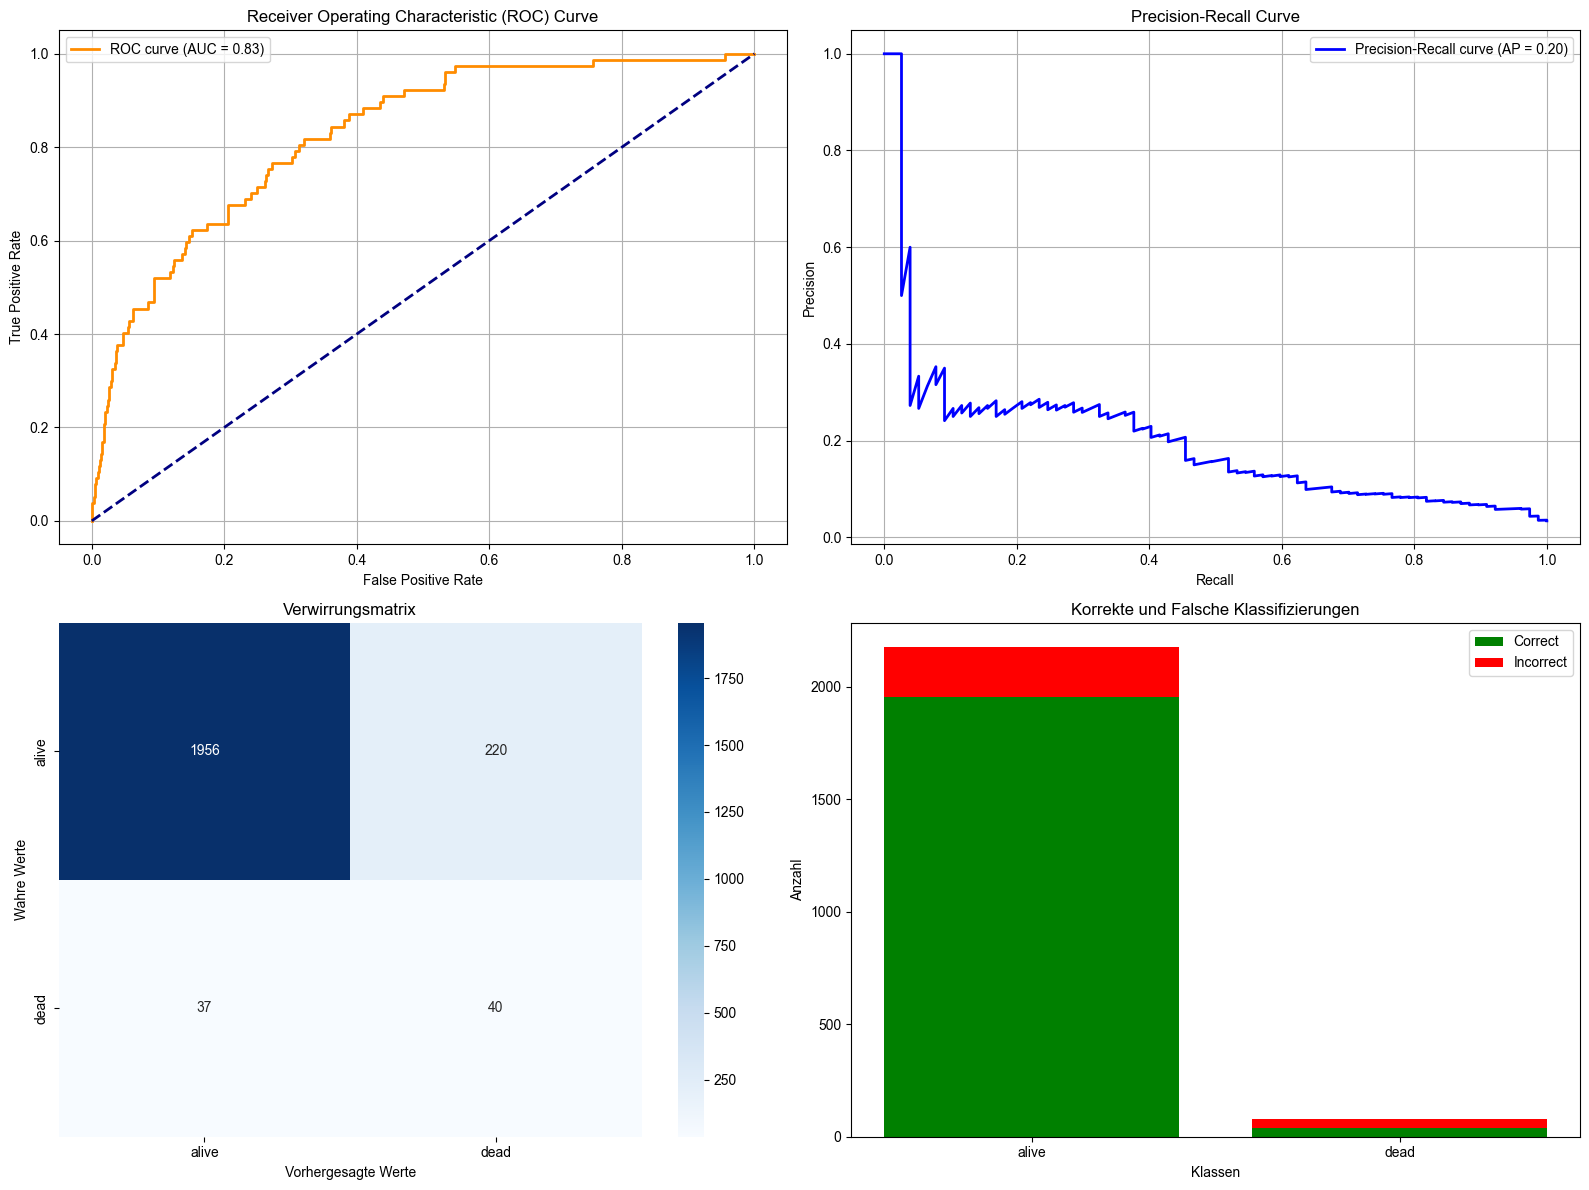

In [18]:
# Import the precision-recall curve metric
from sklearn.metrics import precision_recall_curve

# Use the final trained model to predict labels and probabilities on the test set
preds = final_model.predict(X_test)  # Predict class labels (0 or 1)
pred_proba = final_model.predict_proba(X_test)[:, 1]  # Get probabilities for the positive class

# Calculate various performance metrics based on predictions
accuracy = accuracy_score(y_test, preds)  # Calculate overall accuracy
precision = precision_score(y_test, preds)  # Calculate precision (TP / (TP + FP))
recall = recall_score(y_test, preds)  # Calculate recall (TP / (TP + FN))
f1 = f1_score(y_test, preds)  # Calculate F1 score (harmonic mean of precision and recall)
roc_auc = roc_auc_score(y_test, pred_proba)  # Calculate AUC score for the ROC curve
aucpr = average_precision_score(y_test, pred_proba)  # Calculate average precision score

# Generate the confusion matrix and extract true negatives, false positives, false negatives, and true positives
conf_matrix = confusion_matrix(y_test, preds)  # Create confusion matrix
tn, fp, fn, tp = conf_matrix.ravel()  # Unpack confusion matrix values
FpFn = fp + fn  # Calculate total of false positives and false negatives

# Calculate ROC curve metrics
fpr, tpr, thresholds = roc_curve(y_test, pred_proba)  # Calculate false positive rate and true positive rate
auc_score = auc(fpr, tpr)  # Calculate AUC score from ROC curve metrics

# Print out the calculated metrics for evaluation
print('accuracy:', accuracy)
print('precision:', precision)
print('recall:', recall)
print('f1:', f1)
print('roc_auc:', roc_auc)
print('aucpr:', aucpr)
print('Fp+Fn:', FpFn)
print('auc_score:', auc_score)

# Calculate Precision, Recall, and Thresholds for the Precision-Recall curve
precision, recall, thresholds = precision_recall_curve(y_test, pred_proba)  # Compute precision-recall pairs
average_precision = average_precision_score(y_test, pred_proba)  # Calculate average precision score

# Set up a figure with 2x2 subplots for visualizing the results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot ROC Curve (top left)
axes[0, 0].plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(auc_score))
axes[0, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')  # Plot a diagonal line for reference (random guessing)
axes[0, 0].set_xlabel('False Positive Rate')  # Label for x-axis
axes[0, 0].set_ylabel('True Positive Rate')  # Label for y-axis
axes[0, 0].set_title('Receiver Operating Characteristic (ROC) Curve')  # Title for the plot
axes[0, 0].legend()  # Show legend
axes[0, 0].grid(True)  # Add grid to the plot for better readability

# Plot Precision-Recall Curve (top right)
axes[0, 1].plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve (AP = {:.2f})'.format(average_precision))
axes[0, 1].set_xlabel('Recall')  # Label for x-axis
axes[0, 1].set_ylabel('Precision')  # Label for y-axis
axes[0, 1].set_title('Precision-Recall Curve')  # Title for the plot
axes[0, 1].legend()  # Show legend
axes[0, 1].grid(True)  # Add grid to the plot for better readability

# Plot Confusion Matrix (bottom left)
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["alive", "dead"], yticklabels=["alive", "dead"], ax=axes[1, 0])
axes[1, 0].set_xlabel("Vorhergesagte Werte")  # Label for x-axis (Predicted Values)
axes[1, 0].set_ylabel("Wahre Werte")  # Label for y-axis (True Values)
axes[1, 0].set_title("Verwirrungsmatrix")  # Title for the plot

# Barplot for correct and incorrect classifications (bottom right)
correct_labels = ["alive", "dead"]  # Class labels
correct_counts = [conf_matrix[i, i] for i in range(len(correct_labels))]  # Count correct classifications for each class
incorrect_counts = [sum(conf_matrix[i, :]) - conf_matrix[i, i] for i in range(len(correct_labels))]  # Count incorrect classifications

# Create stacked bar plot for correct and incorrect classifications
axes[1, 1].bar(correct_labels, correct_counts, color='green', label='Correct')  # Bar for correct classifications
axes[1, 1].bar(correct_labels, incorrect_counts, bottom=correct_counts, color='red', label='Incorrect')  # Stacked bar for incorrect classifications
axes[1, 1].set_xlabel('Klassen')  # Label for x-axis (Classes)
axes[1, 1].set_ylabel('Anzahl')  # Label for y-axis (Count)
axes[1, 1].set_title('Korrekte und Falsche Klassifizierungen')  # Title for the plot
axes[1, 1].legend()  # Show legend

# Adjust the layout to avoid overlap of subplots
plt.tight_layout()

# Show the complete figure with all plots
plt.show()


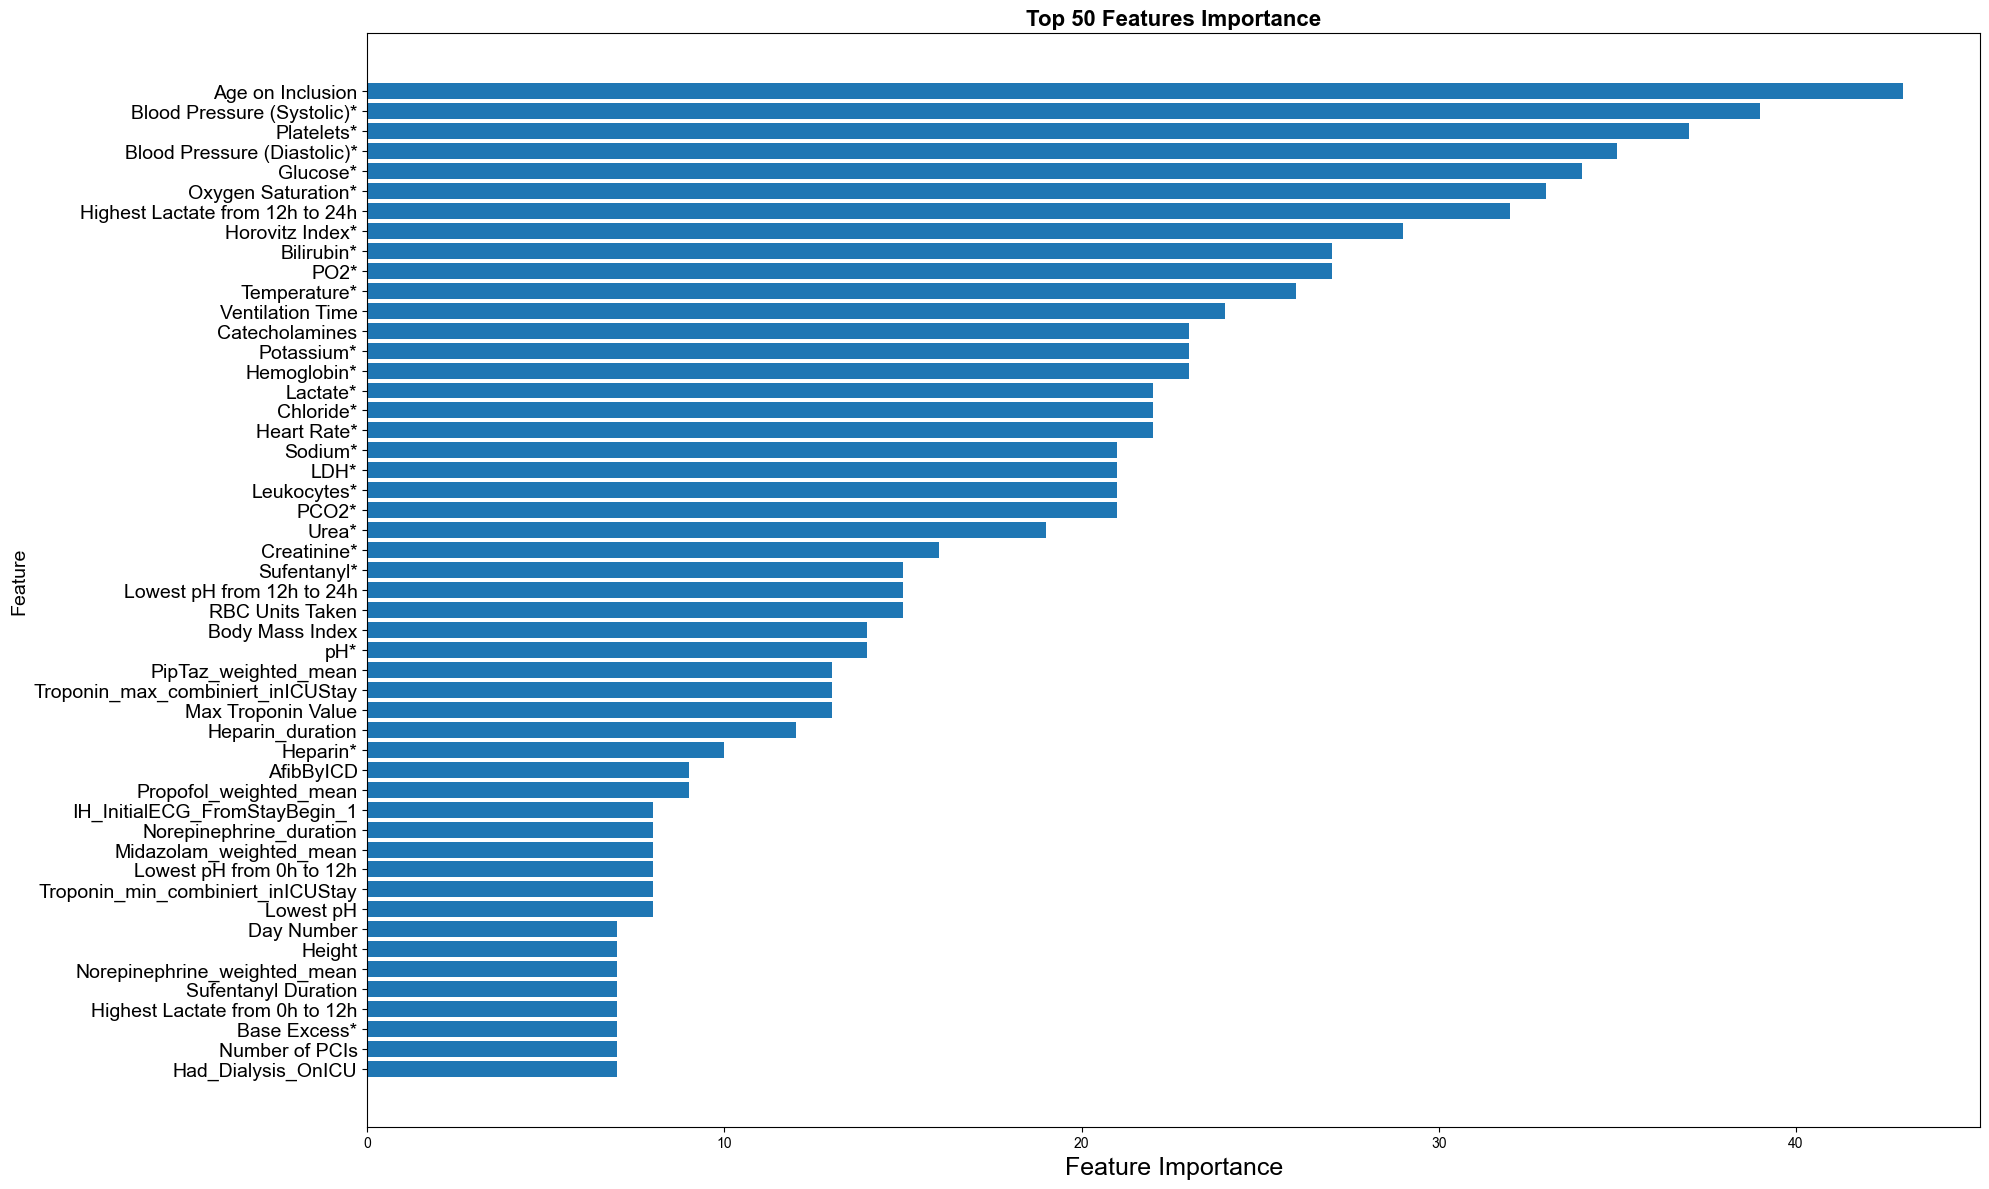

"\n# Create a horizontal bar plot to visualize feature importance\nplt.figure(figsize=(15, 12))  # Reduce the figure size to make the text more readable\nplt.barh(feature_names, feature_importance)  # Create a horizontal bar plot with feature names and their importance\n\n# Label the axes\nplt.xlabel('Feature Importance', fontsize=14)  # Increase font size for better readability\nplt.ylabel('Feature', fontsize=14)  # Increase font size for better readability\nplt.title('Top 50 Features Importance', fontsize=16, fontweight='bold')  # Larger and bold title\n\n# Increase font size of feature names (Y-axis)\nplt.yticks(fontsize=14)  \n\n# Invert the Y-axis to display the most important features at the top\nplt.gca().invert_yaxis()  \n\n# Optimize layout to prevent text from being cut off\nplt.tight_layout()  \n\n# Show the plot on the screen\nplt.show()\n"

In [19]:
# Extract the booster object from the final trained XGBoost model
booster = final_model.get_booster()

# Get the feature importance scores based on the specified importance type ('weight' in this case)
importance = booster.get_score(importance_type='weight')

# Sort the feature importance scores in descending order and select the top 50 features
sorted_importance = sorted(importance.items(), key=lambda x: x[1], reverse=True)[:50]

# Extract feature names and their corresponding importance values from the sorted list
feature_names = [x[0] for x in sorted_importance]  # Get the names of the top 50 features
feature_importance = [x[1] for x in sorted_importance]  # Get the importance scores of the top 50 features


# Mapping der ursprünglichen Feature-Namen zu verständlicheren Bezeichnungen
feature_mapping = {
    "plateletsWeightedMean": "Platelets*",
    "AgeOnInclusion": "Age on Inclusion",
    "Catecholamines": "Catecholamines",
    "HighestLactate_12_24": "Highest Lactate from 12h to 24h",
    "LDHWeightedMean": "LDH*",
    "RRSysWeightedMeanValue": "Blood Pressure (Systolic)*",
    "vent_time": "Ventilation Time",
    "sO2WeightedMeanValue": "Oxygen Saturation*",
    "BilirubineWeightedMean": "Bilirubin*",
    "LowestpH_12_24": "Lowest pH from 12h to 24h",
    "TempWeightedMean": "Temperature*",
    "RRDiaWeightedMeanValue": "Blood Pressure (Diastolic)*",
    "horoviz_WeightedMeanValue": "Horovitz Index*",
    "HRWeightedMean": "Heart Rate*",
    "Troponin_value_max": "Max Troponin Value",
    "ClWeightedMean": "Chloride*",
    "BMI": "Body Mass Index",
    "PHWeightedMean": "pH*",
    "KWeightedMean": "Potassium*",
    "ureaWeightedMean": "Urea*",
    "PCO2WeightedMean": "PCO2*",
    "LactateWeightedMean": "Lactate*",
    "CreatinineWeightedMean": "Creatinine*",
    "LVEFAdmission": "LVEF on Admission",
    "NaWeightedMean": "Sodium*",
    "gluWeightedMean": "Glucose*",
    "leucoWeightedMean": "Leukocytes*",
    "RBCUnitsTaken": "RBC Units Taken",
    "PO2WeightedMean": "PO2*",
    "Troponin_value_min": "Min Troponin Value",
    "Sufentanyl_weighted_mean": "Sufentanyl*",
    "HighestLactate_0_12": "Highest Lactate from 0h to 12h",
    "BEWeightedMean1": "Base Excess*",
    "Endotrachealtube": "Endotracheal Tube",
    "NumberOfPCIs": "Number of PCIs",
    "OH_TotalEpinephrine_factors_1_4.9": "Total Epinephrine on OHCA",
    "Weight": "Weight",
    "Smoking_ex_smoker": "Smoking (Ex-Smoker)",
    "Sufentanyl_duration": "Sufentanyl Duration",
    "Heparin_weighted_mean": "Heparin*",
    "LowestpH_0_12": "Lowest pH from 0h to 12h",
    "HBWeightedMean": "Hemoglobin*",
    "LowestpH": "Lowest pH",
    "TidalVolweightedmean_factors_not_applicable": "Tidal Volume*",
    "Height": "Height",
    "Diabetes_binaer": "Diabetes",
    "HCO3WeightedMean": "HCO3*",
    "Pinspweightedmean_factors_20_24,9": "P inspiratory*",
    "DayNumber": "Day Number",
    "CAD": "Coronary Artery Disease",
    # Hier weitere Features ergänzen...
}

# Falls ein Feature keinen Mapping-Eintrag hat, bleibt der ursprüngliche Name erhalten
mapped_feature_names = [feature_mapping.get(name, name) for name in feature_names]

# Erstelle das Feature-Importance-Plot mit den neuen Namen
plt.figure(figsize=(20, 12))
plt.barh(mapped_feature_names, feature_importance)

# Label-Anpassungen
plt.xlabel('Feature Importance', fontsize=18)
plt.ylabel('Feature', fontsize=14)
plt.title('Top 50 Features Importance', fontsize=16, fontweight='bold')
plt.yticks(fontsize=14)  # Größere Y-Achsen-Beschriftung

# Wichtig: Achse umkehren, damit das wichtigste Feature oben steht
plt.gca().invert_yaxis()

# Layout anpassen, um abgeschnittenen Text zu vermeiden
plt.tight_layout()

# Plot anzeigen
plt.show()


'''
# Create a horizontal bar plot to visualize feature importance
plt.figure(figsize=(15, 12))  # Reduce the figure size to make the text more readable
plt.barh(feature_names, feature_importance)  # Create a horizontal bar plot with feature names and their importance

# Label the axes
plt.xlabel('Feature Importance', fontsize=14)  # Increase font size for better readability
plt.ylabel('Feature', fontsize=14)  # Increase font size for better readability
plt.title('Top 50 Features Importance', fontsize=16, fontweight='bold')  # Larger and bold title

# Increase font size of feature names (Y-axis)
plt.yticks(fontsize=14)  

# Invert the Y-axis to display the most important features at the top
plt.gca().invert_yaxis()  

# Optimize layout to prevent text from being cut off
plt.tight_layout()  

# Show the plot on the screen
plt.show()
'''

In [15]:
# Model Saving
import pickle  # Import the pickle library for object serialization

# Define the filename where the model will be saved
filename = '3#model_for_big_dataset.pkl'

# Open the file in write-binary mode to save the model
with open(filename, 'wb') as file:
    # Serialize the final_model object and write it to the file
    pickle.dump(final_model, file)


In [3]:
# Model Loading
import pickle  # Import the pickle library again for loading the model

# Define the filename where the model is stored
filename = 'Models/3#model_for_big_dataset.pkl'

# Open the file in read-binary mode to load the model
with open(filename, 'rb') as file:
    # Deserialize the model from the file and load it into final_model
    final_model = pickle.load(file)

###Temporal Validity


CUT-OFF: 2014
Old data: 555 patients
New data: 10709 patients

OLD → NEW: Train < 2014, Test >= 2014


  0%|          | 0/50 [00:00<?, ?it/s]

ROC-AUC: 0.6906
PR-AUC: 0.0738

NEW → OLD: Train >= 2014, Test < 2014


  0%|          | 0/50 [00:00<?, ?it/s]

ROC-AUC: 0.8211
PR-AUC: 0.3298

CUT-OFF: 2015
Old data: 934 patients
New data: 10330 patients

OLD → NEW: Train < 2015, Test >= 2015


  0%|          | 0/50 [00:00<?, ?it/s]

... (27 outputs left out)

  0%|          | 0/50 [00:00<?, ?it/s]

ROC-AUC: 0.7900
PR-AUC: 0.2005

NEW → OLD: Train >= 2022, Test < 2022


  0%|          | 0/50 [00:00<?, ?it/s]

ROC-AUC: 0.7826
PR-AUC: 0.1855


FINAL RESULTS
   cutoff_year  ROC_AUC_old_to_new  PR_AUC_old_to_new  ROC_AUC_new_to_old  \
0         2014            0.690579           0.073847            0.821055   
1         2015            0.681333           0.086516            0.780366   
2         2016            0.719646           0.128530            0.814157   
3         2017            0.740035           0.135900            0.827040   
4         2018            0.726656           0.134848            0.834307   
5         2019            0.729240           0.121031            0.805383   
6         2020            0.774004           0.134371            0.811538   
7         2021            0.769647           0.163746            0.787941   
8         2022            0.789993           0.200550            0.782617   

   PR_AUC_new_to_old  n_old  n_new  events_old  events_new  
0           0.329805    555  10709          33         341  
1           0.315650    934  10330          54         320  

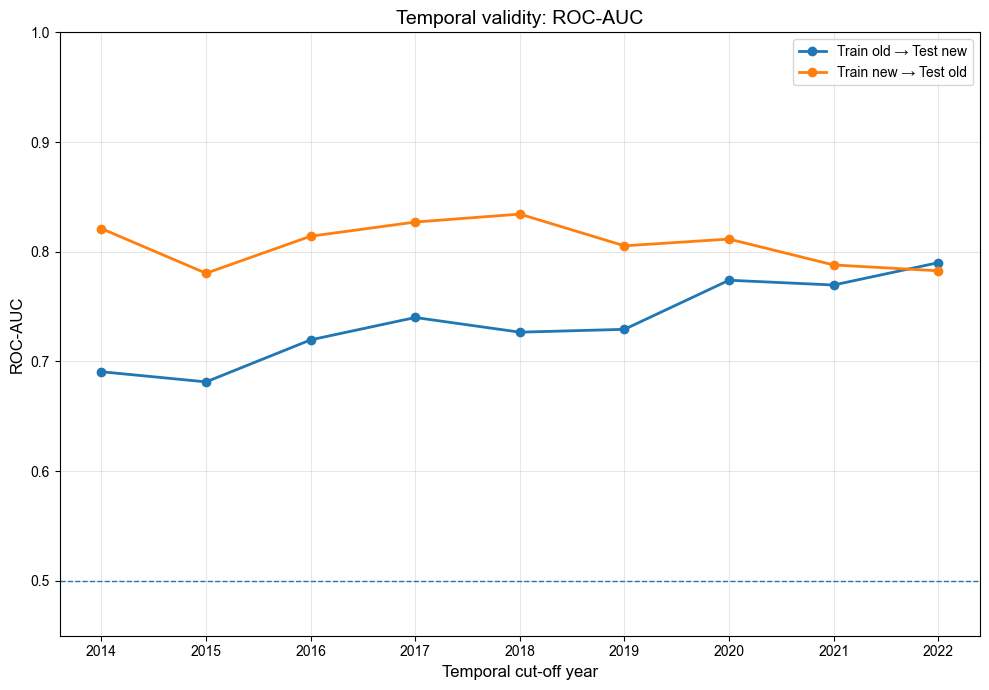

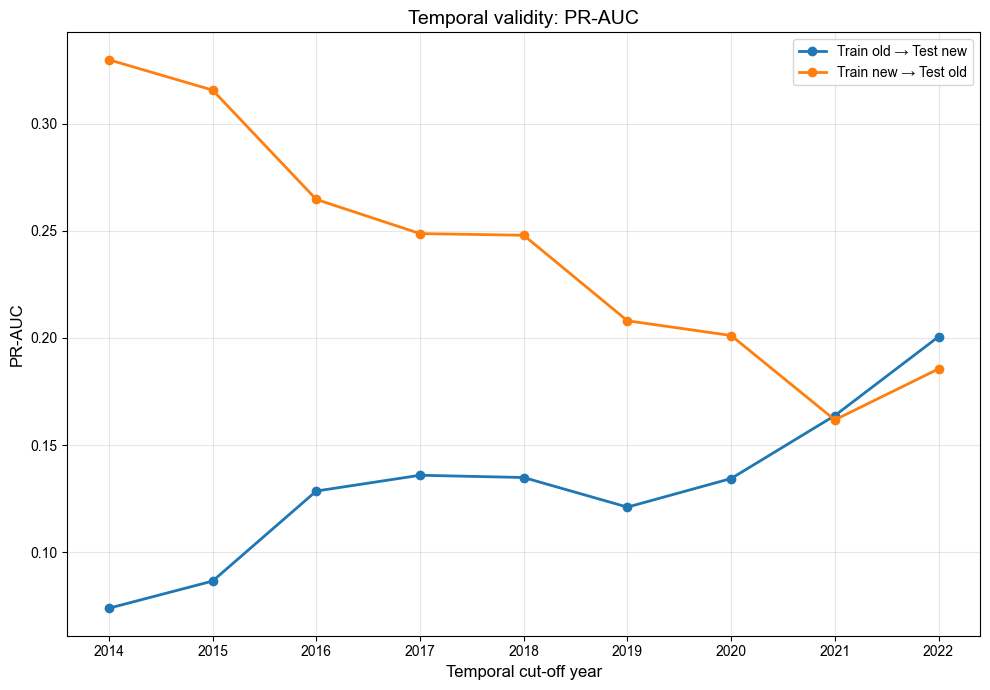

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
import optuna

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from optuna.integration import XGBoostPruningCallback


# ============================================================
# 1. PREPARE DATA
# ============================================================

# Copy original dataframe
df = df_lmu_big.copy()

# Clean data
df = clean_data(
    df,
    encode=True,
    fillna=False,
    Troponin=True,
    log=False,
    scaling=False
)

# Columns that should not be used
col_to_drop = [
    'Death_in3d',
    'DaystillDeath',
    'Death_inHospitalStay',
    'DaysTillICUStay_end',
    'Death_inICUStay',
    'Death_in1w',
    'Death_in2w',
    'Death_in3w',
    'CPConICUDischarge_CPC1',
    'CPConICUDischarge_CPC2',
    'CPConICUDischarge_CPC3',
    'CPConICUDischarge_CPC4',
    'CPConICUDischarge_CPC5'
]

df = df.drop(columns=col_to_drop)

# Make sure Datum is datetime
df['Datum'] = pd.to_datetime(df['Datum'])

label = 'Death_in24h'


# ============================================================
# 2. CUT-OFF YEARS
# ============================================================

cutoff_years = [
    2014,
    2015,
    2016,
    2017,
    2018,
    2019,
    2020,
    2021,
    2022
]


# ============================================================
# 3. FUNCTION TO TRAIN + TEST ONE TEMPORAL SPLIT
# ============================================================

def run_temporal_model(
    train_df,
    test_df,
    label='Death_in24h',
    n_trials=50
):
    
    # --------------------------------------------------------
    # Prepare X and y
    # --------------------------------------------------------
    
    X_train_full = train_df.drop(columns=[label, 'Datum'])
    y_train_full = train_df[label]
    
    X_test = test_df.drop(columns=[label, 'Datum'])
    y_test = test_df[label]
    
    # --------------------------------------------------------
    # Balance training data in the same way as your original
    # approach
    # --------------------------------------------------------
    
    train_combined = pd.concat(
        [X_train_full, y_train_full],
        axis=1
    )
    
    train_combined = train_combined.sample(
        frac=1,
        random_state=2020
    )
    
    dead_df = train_combined[
        train_combined[label] == 1
    ]
    
    alive_df = train_combined[
        train_combined[label] == 0
    ].head(2000)
    
    train_balanced = pd.concat(
        [dead_df, alive_df],
        axis=0
    ).sample(
        frac=1,
        random_state=2020
    )
    
    X_train = train_balanced.drop(columns=[label])
    y_train = train_balanced[label]
    
    
    # --------------------------------------------------------
    # Optuna objective
    # --------------------------------------------------------
    
    def objective(trial):
        
        X_tr, X_eval, y_tr, y_eval = train_test_split(
            X_train,
            y_train,
            test_size=0.15,
            stratify=y_train,
            random_state=2020
        )
        
        param = {
            'objective': 'binary:logistic',
            
            'lambda': trial.suggest_float(
                'lambda', 0.0001, 10.0
            ),
            
            'alpha': trial.suggest_float(
                'alpha', 0.0001, 10.0
            ),
            
            'eta': trial.suggest_float(
                'eta', 0.001, 0.1
            ),
            
            'learning_rate': trial.suggest_float(
                'learning_rate', 0.008, 0.3
            ),
            
            'n_estimators': trial.suggest_int(
                'n_estimators', 50, 1000
            ),
            
            'max_depth': trial.suggest_int(
                'max_depth', 3, 20
            ),
            
            'random_state': 2020,
            
            'min_child_weight': trial.suggest_int(
                'min_child_weight', 1, 30
            ),
            
            'gamma': trial.suggest_float(
                'gamma', 0.009, 10
            ),
            
            'scale_pos_weight': 8,
            
            'max_delta_step': 1
        }
        
        pruning_callback = XGBoostPruningCallback(
            trial,
            "validation_0-aucpr"
        )
        
        model = xgb.XGBClassifier(
            **param,
            early_stopping_rounds=10,
            device="cuda",
            eval_metric="aucpr",
            callbacks=[pruning_callback]
        )
        
        model.fit(
            X_tr,
            y_tr,
            eval_set=[(X_eval, y_eval)],
            verbose=False
        )
        
        pred_proba = model.predict_proba(
            X_eval
        )[:, 1]
        
        return roc_auc_score(
            y_eval,
            pred_proba
        )
    
    
    # --------------------------------------------------------
    # Optuna optimization
    # --------------------------------------------------------
    
    study = optuna.create_study(
        direction='maximize'
    )
    
    study.optimize(
        objective,
        n_trials=n_trials,
        show_progress_bar=True
    )
    
    best_params = study.best_trial.params
    
    # --------------------------------------------------------
    # Train final model
    # --------------------------------------------------------
    
    final_model = xgb.XGBClassifier(
        **best_params,
        objective='binary:logistic',
        eval_metric='aucpr',
        device='cuda',
        random_state=2020
    )
    
    final_model.fit(
        X_train,
        y_train,
        verbose=False
    )
    
    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------
    
    pred_proba = final_model.predict_proba(
        X_test
    )[:, 1]
    
    roc_auc = roc_auc_score(
        y_test,
        pred_proba
    )
    
    pr_auc = average_precision_score(
        y_test,
        pred_proba
    )
    
    return roc_auc, pr_auc


# ============================================================
# 4. RUN ALL TEMPORAL CUT-OFFS
# ============================================================

results = []


for cutoff_year in cutoff_years:
    
    print("\n" + "=" * 70)
    print(f"CUT-OFF: {cutoff_year}")
    print("=" * 70)
    
    cutoff_date = pd.Timestamp(
        f"{cutoff_year}-01-01"
    )
    
    old_data = df[
        df['Datum'] < cutoff_date
    ].copy()
    
    new_data = df[
        df['Datum'] >= cutoff_date
    ].copy()
    
    print(
        f"Old data: {len(old_data)} patients"
    )
    
    print(
        f"New data: {len(new_data)} patients"
    )
    
    # --------------------------------------------------------
    # Check that both groups contain both classes
    # --------------------------------------------------------
    
    if (
        len(old_data) == 0
        or len(new_data) == 0
        or old_data[label].nunique() < 2
        or new_data[label].nunique() < 2
    ):
        print(
            "Skipping: insufficient data or only one class."
        )
        continue
    
    
    # ========================================================
    # A) OLD → NEW
    # Train on old data
    # Test on new data
    # ========================================================
    
    print(
        f"\nOLD → NEW: "
        f"Train < {cutoff_year}, "
        f"Test >= {cutoff_year}"
    )
    
    roc_old_new, pr_old_new = run_temporal_model(
        train_df=old_data,
        test_df=new_data,
        label=label,
        n_trials=50
    )
    
    print(
        f"ROC-AUC: {roc_old_new:.4f}"
    )
    
    print(
        f"PR-AUC: {pr_old_new:.4f}"
    )
    
    
    # ========================================================
    # B) NEW → OLD
    # Train on new data
    # Test on old data
    # ========================================================
    
    print(
        f"\nNEW → OLD: "
        f"Train >= {cutoff_year}, "
        f"Test < {cutoff_year}"
    )
    
    roc_new_old, pr_new_old = run_temporal_model(
        train_df=new_data,
        test_df=old_data,
        label=label,
        n_trials=50
    )
    
    print(
        f"ROC-AUC: {roc_new_old:.4f}"
    )
    
    print(
        f"PR-AUC: {pr_new_old:.4f}"
    )
    
    
    # --------------------------------------------------------
    # Save results
    # --------------------------------------------------------
    
    results.append({
        'cutoff_year': cutoff_year,
        
        'ROC_AUC_old_to_new': roc_old_new,
        'PR_AUC_old_to_new': pr_old_new,
        
        'ROC_AUC_new_to_old': roc_new_old,
        'PR_AUC_new_to_old': pr_new_old,
        
        'n_old': len(old_data),
        'n_new': len(new_data),
        
        'events_old': old_data[label].sum(),
        'events_new': new_data[label].sum()
    })


# ============================================================
# 5. RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(results)

print("\n\nFINAL RESULTS")
print(results_df)


# ============================================================
# 6. PLOT ROC-AUC
# ============================================================

plt.figure(figsize=(10, 7))

plt.plot(
    results_df['cutoff_year'],
    results_df['ROC_AUC_old_to_new'],
    marker='o',
    linewidth=2,
    label='Train old → Test new'
)

plt.plot(
    results_df['cutoff_year'],
    results_df['ROC_AUC_new_to_old'],
    marker='o',
    linewidth=2,
    label='Train new → Test old'
)

plt.axhline(
    0.5,
    linestyle='--',
    linewidth=1
)

plt.xlabel(
    'Temporal cut-off year',
    fontsize=12
)

plt.ylabel(
    'ROC-AUC',
    fontsize=12
)

plt.title(
    'Temporal validity: ROC-AUC',
    fontsize=14
)

plt.xticks(
    results_df['cutoff_year']
)

plt.ylim(0.45, 1.0)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 7. PLOT PR-AUC
# ============================================================

plt.figure(figsize=(10, 7))

plt.plot(
    results_df['cutoff_year'],
    results_df['PR_AUC_old_to_new'],
    marker='o',
    linewidth=2,
    label='Train old → Test new'
)

plt.plot(
    results_df['cutoff_year'],
    results_df['PR_AUC_new_to_old'],
    marker='o',
    linewidth=2,
    label='Train new → Test old'
)

plt.xlabel(
    'Temporal cut-off year',
    fontsize=12
)

plt.ylabel(
    'PR-AUC',
    fontsize=12
)

plt.title(
    'Temporal validity: PR-AUC',
    fontsize=14
)

plt.xticks(
    results_df['cutoff_year']
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.show()

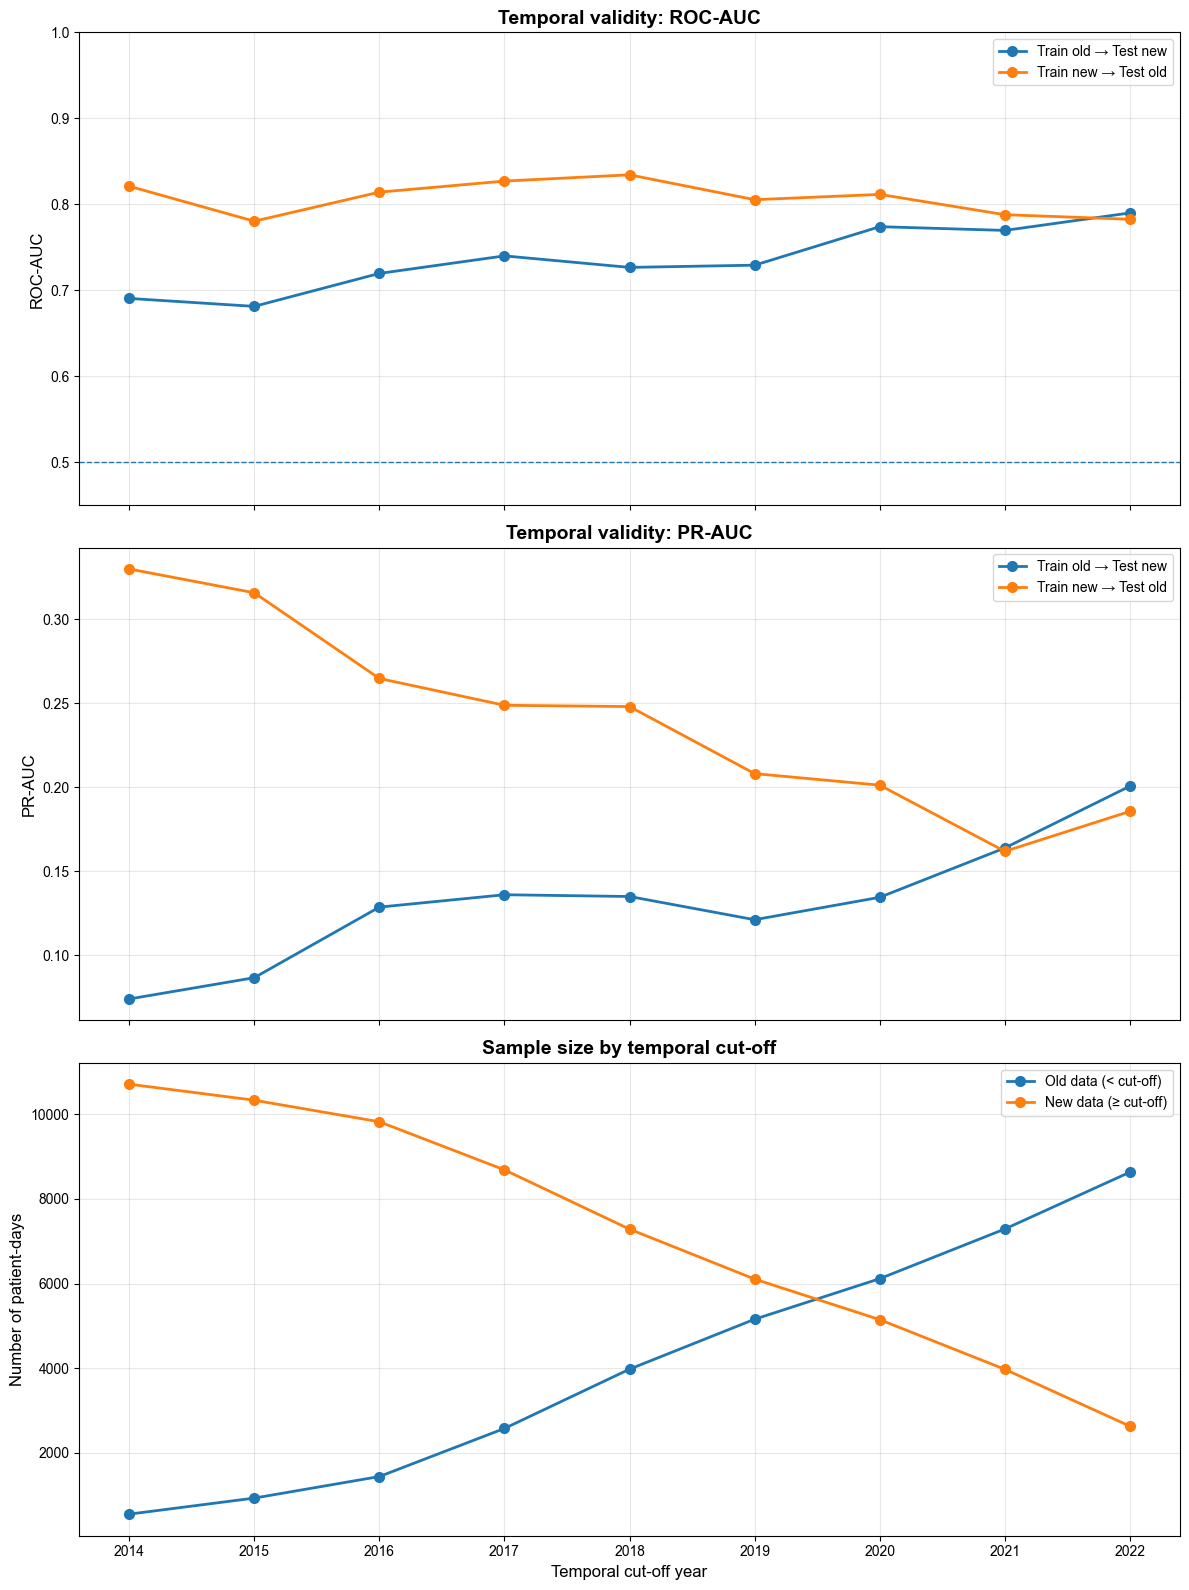

In [4]:
# ============================================================
# 6. COMBINED FIGURE: ROC-AUC, PR-AUC AND SAMPLE SIZE
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 16),
    sharex=True
)

# ------------------------------------------------------------
# Common x-axis
# ------------------------------------------------------------

years = results_df['cutoff_year']


# ============================================================
# SUBPLOT 1: ROC-AUC
# ============================================================

axes[0].plot(
    years,
    results_df['ROC_AUC_old_to_new'],
    marker='o',
    linewidth=2,
    markersize=7,
    label='Train old → Test new'
)

axes[0].plot(
    years,
    results_df['ROC_AUC_new_to_old'],
    marker='o',
    linewidth=2,
    markersize=7,
    label='Train new → Test old'
)

# Reference line for random classifier
axes[0].axhline(
    0.5,
    linestyle='--',
    linewidth=1
)

axes[0].set_ylabel(
    'ROC-AUC',
    fontsize=12
)

axes[0].set_title(
    'Temporal validity: ROC-AUC',
    fontsize=14,
    fontweight='bold'
)

axes[0].set_ylim(
    0.45,
    1.0
)

axes[0].legend(
    loc='best',
    frameon=True
)

axes[0].grid(
    True,
    alpha=0.3
)


# ============================================================
# SUBPLOT 2: PR-AUC
# ============================================================

axes[1].plot(
    years,
    results_df['PR_AUC_old_to_new'],
    marker='o',
    linewidth=2,
    markersize=7,
    label='Train old → Test new'
)

axes[1].plot(
    years,
    results_df['PR_AUC_new_to_old'],
    marker='o',
    linewidth=2,
    markersize=7,
    label='Train new → Test old'
)

axes[1].set_ylabel(
    'PR-AUC',
    fontsize=12
)

axes[1].set_title(
    'Temporal validity: PR-AUC',
    fontsize=14,
    fontweight='bold'
)

axes[1].legend(
    loc='best',
    frameon=True
)

axes[1].grid(
    True,
    alpha=0.3
)


# ============================================================
# SUBPLOT 3: SAMPLE SIZE
# ============================================================

axes[2].plot(
    years,
    results_df['n_old'],
    marker='o',
    linewidth=2,
    markersize=7,
    label='Old data (< cut-off)'
)

axes[2].plot(
    years,
    results_df['n_new'],
    marker='o',
    linewidth=2,
    markersize=7,
    label='New data (≥ cut-off)'
)

axes[2].set_xlabel(
    'Temporal cut-off year',
    fontsize=12
)

axes[2].set_ylabel(
    'Number of patient-days',
    fontsize=12
)

axes[2].set_title(
    'Sample size by temporal cut-off',
    fontsize=14,
    fontweight='bold'
)

axes[2].legend(
    loc='best',
    frameon=True
)

axes[2].grid(
    True,
    alpha=0.3
)


# ============================================================
# COMMON FORMATTING
# ============================================================

axes[2].set_xticks(years)

for ax in axes:
    ax.tick_params(
        axis='both',
        labelsize=10
    )

plt.tight_layout()

plt.show()